# Telco Customer Churn – Comparison of Five Classification Models
**M.Tech (AIML) · Machine Learning · Assignment 2** | Name: `Gaurav Sharma` | BITS ID: `2026AJ05141`

**Objective:** predict whether a telecom customer will churn (`Yes`) or stay (`No`) from 19 account/service features,
and compare Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes and SVM using Accuracy, AUC, Precision, Recall, F1 and MCC.

**How to run:** `Kernel → Restart & Run All`. If Section 1 asks you to restart the kernel, do so and run it again.
This notebook also creates every file the GitHub repo and Streamlit app need (`model/*.joblib`, `test_data.csv`, `churn_utils.py`).

## 1. Environment check

In [3]:
import subprocess
import sys


def install_package(requirement: str) -> None:
    """Install a package into the interpreter that runs this notebook."""
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", requirement])


def ensure_compatible_environment() -> bool:
    """Verify NumPy/SciPy/scikit-learn import together; repair a known NumPy/SciPy mismatch.

    Returns True when the environment is ready, False when the kernel must be restarted.
    """
    try:
        import numpy
        import scipy.sparse
        import scipy.stats
        import sklearn
    except (ImportError, AttributeError) as error:
        print("Incompatible NumPy/SciPy detected:", error)
        install_package("scipy<1.14")
        print(">>> Repaired. Restart the kernel (Kernel > Restart), then run this cell again. <<<")
        return False

    for module_name in ["pandas", "joblib", "matplotlib", "tabulate"]:
        try:
            __import__(module_name)
        except ImportError:
            install_package(module_name)

    print(f"NumPy {numpy.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__} -> environment OK")
    return True


ENVIRONMENT_READY = ensure_compatible_environment()
assert ENVIRONMENT_READY, "Restart the kernel and run this cell again."

NumPy 2.5.4 | SciPy 1.18.1 | scikit-learn 1.9.1 -> environment OK


In [4]:
import datetime
import getpass
import platform
import socket

print("Executed on :", datetime.datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print("Host / user :", socket.gethostname(), "/", getpass.getuser())
print("Python      :", platform.python_version(), "on", platform.system())

Executed on : 2026-10-29 01:46:50
Host / user : ip-10-3-19-149.ap-south-1.compute.internal / s2026aj05141
Python      : 3.12.7 on Linux


## 2. Shared configuration (`churn_utils.py`)
Column lists, model file paths and two cleaning helpers. The Streamlit app imports this same file.

In [6]:
%%writefile churn_utils.py
"""Shared constants and helper functions for the Telco churn project."""
import pandas as pd

TARGET_COL = "Churn"
ID_COL = "customerID"
POSITIVE_LABEL = "Yes"

NUMERIC_FEATURES = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]
CATEGORICAL_FEATURES = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod",
]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

MODEL_FILES = {
    "Logistic Regression": "model/logistic_regression.joblib",
    "Decision Tree": "model/decision_tree.joblib",
    "KNN": "model/knn.joblib",
    "Naive Bayes": "model/naive_bayes.joblib",
    "Support Vector Machine": "model/svm.joblib",
}


def clean_frame(df: pd.DataFrame) -> pd.DataFrame:
    """Drop the identifier column and convert TotalCharges to numeric (blank strings become NaN)."""
    cleaned = df.copy()
    cleaned.columns = [name.strip() for name in cleaned.columns]
    if ID_COL in cleaned.columns:
        cleaned = cleaned.drop(columns=[ID_COL])
    cleaned["TotalCharges"] = pd.to_numeric(cleaned["TotalCharges"], errors="coerce")
    return cleaned


def encode_target(labels: pd.Series) -> pd.Series:
    """Convert Yes/No churn labels (or 1/0) into integers, with churn = 1."""
    text = labels.astype(str).str.strip()
    return text.isin([POSITIVE_LABEL, "1", "True", "true"]).astype(int)


Writing churn_utils.py


## 3. Dataset
**IBM Telco Customer Churn** (Kaggle: *blastchar/telco-customer-churn*): 7,043 customers, 19 input features, binary target `Churn`.
If the Lab has no internet access, download the CSV on your laptop and upload it as `data/telco_raw.csv` (path set below).

In [8]:
import os
import urllib.request

import pandas as pd

from churn_utils import (CATEGORICAL_FEATURES, FEATURES, MODEL_FILES, NUMERIC_FEATURES,
                         TARGET_COL, clean_frame, encode_target)

RANDOM_STATE = 42
TEST_FRACTION = 0.20
DATASET_PATH = "data/telco_raw.csv"
DATASET_URL = ("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/"
               "master/data/Telco-Customer-Churn.csv")

os.makedirs("data", exist_ok=True)
os.makedirs("model", exist_ok=True)


def fetch_dataset_file(local_path: str, url: str) -> None:
    """Make sure the raw CSV exists locally, downloading it only when it is missing."""
    if os.path.exists(local_path):
        return
    try:
        urllib.request.urlretrieve(url, local_path)
    except Exception as download_error:
        raise FileNotFoundError(
            f"Dataset not found and download failed ({download_error}). "
            f"Upload the CSV to '{local_path}' and run this cell again.") from download_error


def prepare_features_and_target(raw_frame: pd.DataFrame):
    """Return the cleaned feature table and the 0/1 churn target."""
    cleaned = clean_frame(raw_frame)
    return cleaned[FEATURES], encode_target(cleaned[TARGET_COL])


fetch_dataset_file(DATASET_PATH, DATASET_URL)
raw_data = pd.read_csv(DATASET_PATH)
features, target = prepare_features_and_target(raw_data)

assert len(features) >= 500, "Dataset must have at least 500 instances."
assert features.shape[1] >= 12, "Dataset must have at least 12 features."
print(f"Instances: {len(features)} | Features: {features.shape[1]} | Churn rate: {target.mean():.1%}")
print("Blank TotalCharges values (imputed later):", int(features["TotalCharges"].isna().sum()))
raw_data.head()

Instances: 7043 | Features: 19 | Churn rate: 26.5%
Blank TotalCharges values (imputed later): 11


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 4. Train/test split
Stratified 80/20 split. The test rows are saved as `test_data.csv` (features + `Churn`) for the Streamlit app.

In [10]:
from sklearn.model_selection import train_test_split


def split_and_export_test_set(features: pd.DataFrame, target: pd.Series, export_path: str = "test_data.csv"):
    """Create a stratified train/test split and write the held-out rows to a CSV file."""
    x_train, x_test, y_train, y_test = train_test_split(
        features, target, test_size=TEST_FRACTION, stratify=target, random_state=RANDOM_STATE)
    export_frame = x_test.copy()
    export_frame[TARGET_COL] = y_test.map({1: "Yes", 0: "No"})
    export_frame.to_csv(export_path, index=False)
    return x_train, x_test, y_train, y_test


x_train, x_test, y_train, y_test = split_and_export_test_set(features, target)
print(f"Training rows: {len(x_train)} | Test rows: {len(x_test)} (saved to test_data.csv)")

Training rows: 5634 | Test rows: 1409 (saved to test_data.csv)


## 5. Models and metrics

In [12]:
import warnings

import joblib
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, f1_score, matthews_corrcoef,
                             precision_score, recall_score, roc_auc_score)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

warnings.filterwarnings("ignore")


def build_preprocessing_pipeline() -> ColumnTransformer:
    """Median-impute + scale numeric columns; one-hot encode categorical columns (dense output)."""
    numeric_steps = Pipeline([("impute_median", SimpleImputer(strategy="median")),
                              ("standardise", StandardScaler())])
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)   # scikit-learn >= 1.2
    except TypeError:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)          # older versions
    return ColumnTransformer([("numeric", numeric_steps, NUMERIC_FEATURES),
                              ("categorical", encoder, CATEGORICAL_FEATURES)])


def build_candidate_classifiers() -> dict:
    """The five classifiers required by the assignment, keyed by display name."""
    return {
        "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
        "Decision Tree": DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE),
        "KNN": KNeighborsClassifier(n_neighbors=15),
        "Naive Bayes": GaussianNB(),
        "Support Vector Machine": SVC(kernel="rbf", C=1.0, probability=True, random_state=RANDOM_STATE),
    }


def compute_binary_metrics(y_true, y_predicted, churn_probability) -> dict:
    """Six evaluation metrics; precision/recall/F1 refer to the positive class (churn)."""
    return {
        "Accuracy": accuracy_score(y_true, y_predicted),
        "AUC": roc_auc_score(y_true, churn_probability),
        "Precision": precision_score(y_true, y_predicted),
        "Recall": recall_score(y_true, y_predicted),
        "F1": f1_score(y_true, y_predicted),
        "MCC": matthews_corrcoef(y_true, y_predicted),
    }


def train_evaluate_and_save_all(classifiers: dict):
    """Fit each classifier inside a full pipeline, score it on the test set and save it with joblib."""
    metric_rows, fitted_pipelines, test_predictions = [], {}, {}
    for model_name, classifier in classifiers.items():
        pipeline = Pipeline([("preprocess", build_preprocessing_pipeline()), ("classifier", classifier)])
        pipeline.fit(x_train, y_train)
        predicted_labels = pipeline.predict(x_test)
        churn_probability = pipeline.predict_proba(x_test)[:, 1]
        metric_rows.append({"ML Model Name": model_name,
                            **compute_binary_metrics(y_test, predicted_labels, churn_probability)})
        joblib.dump(pipeline, MODEL_FILES[model_name])
        fitted_pipelines[model_name] = pipeline
        test_predictions[model_name] = predicted_labels
        print(f"trained and saved -> {MODEL_FILES[model_name]}")
    return pd.DataFrame(metric_rows).round(4), fitted_pipelines, test_predictions


metrics_table, fitted_pipelines, test_predictions = train_evaluate_and_save_all(build_candidate_classifiers())
metrics_table.to_csv("model/metrics_summary.csv", index=False)
metrics_table

trained and saved -> model/logistic_regression.joblib
trained and saved -> model/decision_tree.joblib
trained and saved -> model/knn.joblib
trained and saved -> model/naive_bayes.joblib
trained and saved -> model/svm.joblib


,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.8055,0.8419,0.6572,0.5588,0.6040,0.4790
1,Decision Tree,0.7970,0.8383,0.6679,0.4679,0.5503,0.4357
2,KNN,0.7771,0.8215,0.5833,0.5615,0.5722,0.4217
3,Naive Bayes,0.6948,0.8074,0.4589,0.8369,0.5928,0.4245
4,Support Vector Machine,0.7913,0.7905,0.6418,0.4840,0.5518,0.4264


## 6. Comparison table and best model

In [14]:
def print_comparison_summary(table: pd.DataFrame) -> None:
    """Print the metrics table (markdown if available) and the best model by MCC."""
    try:
        print(table.to_markdown(index=False))
    except ImportError:
        print(table.to_string(index=False))
    best_row = table.loc[table["MCC"].idxmax()]
    print(f"\nBest model by MCC: {best_row['ML Model Name']} (MCC = {best_row['MCC']:.4f})")


print_comparison_summary(metrics_table)

| ML Model Name          |   Accuracy |    AUC |   Precision |   Recall |     F1 |    MCC |
|:-----------------------|-----------:|-------:|------------:|---------:|-------:|-------:|
| Logistic Regression    |     0.8055 | 0.8419 |      0.6572 |   0.5588 | 0.604  | 0.479  |
| Decision Tree          |     0.797  | 0.8383 |      0.6679 |   0.4679 | 0.5503 | 0.4357 |
| KNN                    |     0.7771 | 0.8215 |      0.5833 |   0.5615 | 0.5722 | 0.4217 |
| Naive Bayes            |     0.6948 | 0.8074 |      0.4589 |   0.8369 | 0.5928 | 0.4245 |
| Support Vector Machine |     0.7913 | 0.7905 |      0.6418 |   0.484  | 0.5518 | 0.4264 |

Best model by MCC: Logistic Regression (MCC = 0.4790)


## 7. Confusion matrices and classification reports

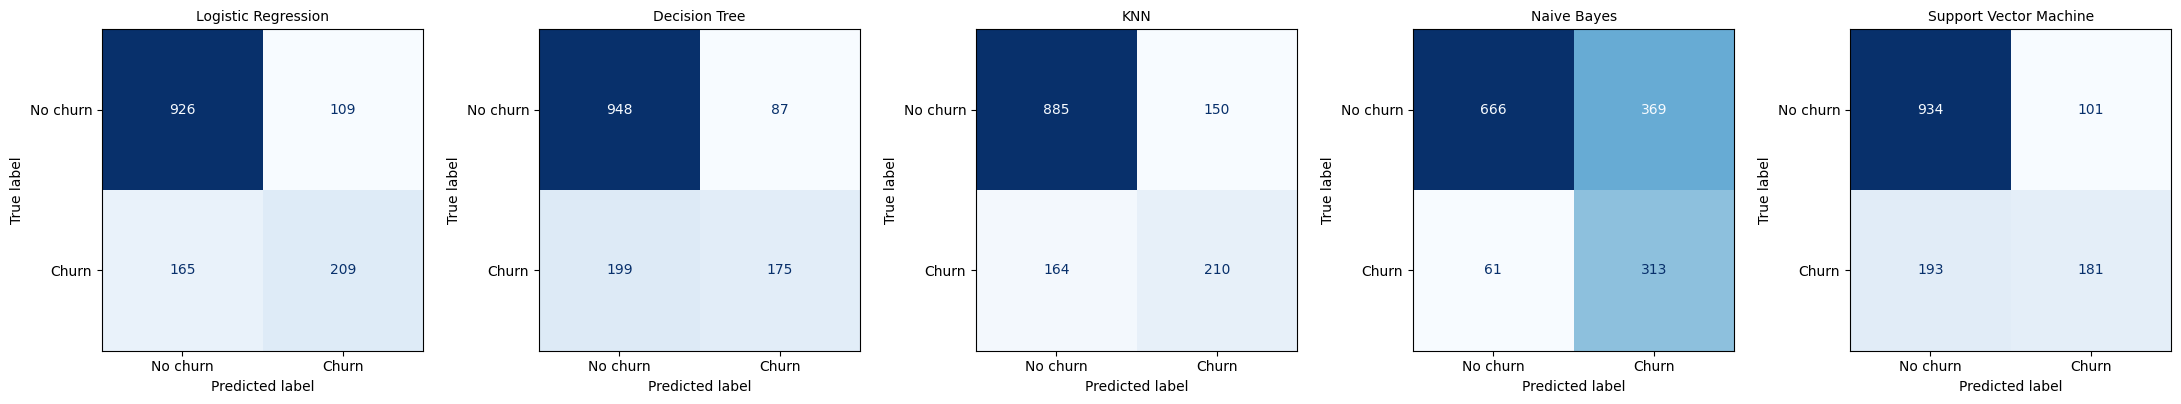

Logistic Regression
              precision    recall  f1-score   support

    No churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409

Decision Tree
              precision    recall  f1-score   support

    No churn       0.83      0.92      0.87      1035
       Churn       0.67      0.47      0.55       374

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.71      1409
weighted avg       0.78      0.80      0.78      1409

KNN
              precision    recall  f1-score   support

    No churn       0.84      0.86      0.85      1035
       Churn       0.58      0.56      0.57       374

    accuracy                           0.78      1409
   macro avg       0.71      0.71      0.71      1409
weighted avg       0.77      0.78   

In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix


def plot_confusion_matrices(true_labels, predictions_by_model: dict) -> None:
    """Draw one confusion matrix per model in a single row."""
    figure, axes = plt.subplots(1, len(predictions_by_model), figsize=(4.4 * len(predictions_by_model), 4))
    for axis, (model_name, predicted) in zip(axes, predictions_by_model.items()):
        ConfusionMatrixDisplay(confusion_matrix(true_labels, predicted),
                               display_labels=["No churn", "Churn"]).plot(ax=axis, cmap="Blues", colorbar=False)
        axis.set_title(model_name, fontsize=10)
    plt.tight_layout()
    plt.show()


def print_classification_reports(true_labels, predictions_by_model: dict) -> None:
    """Print a scikit-learn classification report for each model."""
    for model_name, predicted in predictions_by_model.items():
        print("=" * 60)
        print(model_name)
        print(classification_report(true_labels, predicted, target_names=["No churn", "Churn"]))


plot_confusion_matrices(y_test, test_predictions)
print_classification_reports(y_test, test_predictions)

## 8. Verify the saved models (this is what the Streamlit app does)
Reload each `.joblib` file, score `test_data.csv` and check the results equal the metrics above.

In [18]:
def verify_saved_models(test_csv_path: str = "test_data.csv") -> pd.DataFrame:
    """Reload every saved model, predict on the exported test file and compare with the in-memory metrics."""
    exported = pd.read_csv(test_csv_path)
    exported_features = clean_frame(exported)[FEATURES]
    exported_target = encode_target(exported[TARGET_COL])
    rows = []
    for model_name, model_path in MODEL_FILES.items():
        reloaded = joblib.load(model_path)
        predicted = reloaded.predict(exported_features)
        accuracy = accuracy_score(exported_target, predicted)
        expected = float(metrics_table.loc[metrics_table["ML Model Name"] == model_name, "Accuracy"].iloc[0])
        rows.append({"Model": model_name, "Accuracy (reloaded)": round(accuracy, 4),
                     "Matches training run": abs(round(accuracy, 4) - expected) < 1e-4})
    return pd.DataFrame(rows)


verification = verify_saved_models()
assert verification["Matches training run"].all(), "A saved model does not reproduce its metrics."
verification

,Model,Accuracy (reloaded),Matches training run
0,Logistic Regression,0.8055,True
1,Decision Tree,0.7970,True
2,KNN,0.7771,True
3,Naive Bayes,0.6948,True
4,Support Vector Machine,0.7913,True


## 9. Final summary (take the BITS Lab screenshot after this cell)

In [20]:
def print_final_summary() -> None:
    """List generated artefacts and repeat the final metrics table."""
    artefacts = ["churn_utils.py", "test_data.csv", *MODEL_FILES.values(), "model/metrics_summary.csv"]
    print("Generated files:")
    for path in artefacts:
        print(f"  {path:35s} {os.path.getsize(path):>10,d} bytes")
    print()
    print(metrics_table.to_string(index=False))


print_final_summary()

Generated files:
  churn_utils.py                           1,512 bytes
  test_data.csv                          179,303 bytes
  model/logistic_regression.joblib         9,114 bytes
  model/decision_tree.joblib              17,940 bytes
  model/knn.joblib                     2,082,015 bytes
  model/naive_bayes.joblib                10,082 bytes
  model/svm.joblib                     1,019,990 bytes
  model/metrics_summary.csv                  330 bytes

         ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.8055 0.8419     0.6572  0.5588 0.6040 0.4790
         Decision Tree    0.7970 0.8383     0.6679  0.4679 0.5503 0.4357
                   KNN    0.7771 0.8215     0.5833  0.5615 0.5722 0.4217
           Naive Bayes    0.6948 0.8074     0.4589  0.8369 0.5928 0.4245
Support Vector Machine    0.7913 0.7905     0.6418  0.4840 0.5518 0.4264


## 10. Next steps
Copy `app.py`, `requirements.txt`, `README.md`, `churn_utils.py`, `test_data.csv`, `data/` and `model/` to your GitHub repository,
then deploy `app.py` on Streamlit Community Cloud. The scikit-learn version printed in Section 1 must match the pin in `requirements.txt`.